In [2]:
# Code for Random Forest concept (mostly bagging, this code will give you the feel, but its not exactly Random Forest):
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification


In [3]:
X,y = make_classification(n_features=5,n_redundant=0,n_informative=5,n_clusters_per_class=1)

In [4]:
df = pd.DataFrame(X,columns=['col1','col2','col3','col4','col5'])
df['target'] = y
print(df.shape)
df.head()

(100, 6)


,col1,col2,col3,col4,col5,target
0,0.355627,-1.820137,3.218475,1.064526,-0.934446,1
1,-0.118630,1.016930,-0.110961,-0.357542,-1.868659,0
2,-2.316996,0.125352,-2.073142,0.047183,0.410724,0
3,-0.521486,0.242851,-0.493006,2.376840,-3.164037,0
4,0.260756,-1.693405,0.339215,2.093384,-3.077037,1


In [5]:
#function for row sampling
def sample_rows(df,percent):
  return df.sample(int(percent*df.shape[0]),replace=True)

In [6]:
#function for feature sampling
def sample_features(df,percent):
  cols = random.sample(df.columns.tolist()[:,-1],int(percent*df.shape[1]))
  return df[cols]

In [7]:
#function for combined sampling
def combined_sampling(df,row_percent,col_percent):
  new_df = sample_rows(df,row_percent)
  return sample_features(new_df,col_percent)

In [8]:
df1 = sample_rows(df,0.1)      #dataset1 for DecisionTree1

In [9]:
df2 = sample_rows(df,0.1)      #dataset2 for DecisionTree2

In [10]:
df3 = sample_rows(df,0.1)      #dataset3 for DecisionTree3

In [11]:
df1.shape

(10, 6)

In [12]:
df2.shape

(10, 6)

In [13]:
df3.shape

(10, 6)

In [14]:
from sklearn.tree import DecisionTreeClassifier
clf1 = DecisionTreeClassifier()
clf2 = DecisionTreeClassifier()
clf3 = DecisionTreeClassifier()

In [15]:
clf1.fit(df1.iloc[:,0:5],df1.iloc[:,-1])
clf2.fit(df2.iloc[:,0:5],df2.iloc[:,-1])
clf3.fit(df3.iloc[:,0:5],df3.iloc[:,-1])

DecisionTreeClassifier()

In [16]:
from sklearn.tree import plot_tree

[Text(0.4, 0.8333333333333334, 'x[2] <= -0.189\ngini = 0.48\nsamples = 10\nvalue = [4, 6]'),
 Text(0.2, 0.5, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.30000000000000004, 0.6666666666666667, 'True  '),
 Text(0.6, 0.5, 'x[4] <= -4.221\ngini = 0.245\nsamples = 7\nvalue = [1, 6]'),
 Text(0.5, 0.6666666666666667, '  False'),
 Text(0.4, 0.16666666666666666, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.8, 0.16666666666666666, 'gini = 0.0\nsamples = 6\nvalue = [0, 6]')]

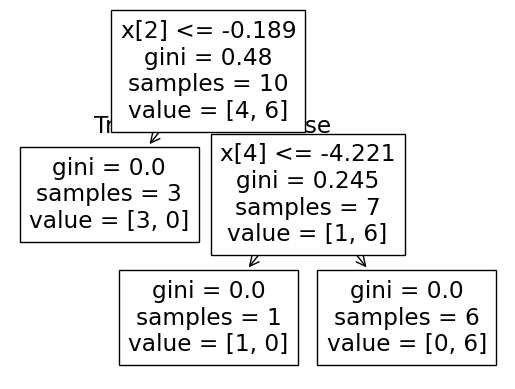

In [17]:
plot_tree(clf1)

[Text(0.6, 0.8333333333333334, 'x[3] <= 1.664\ngini = 0.48\nsamples = 10\nvalue = [4, 6]'),
 Text(0.4, 0.5, 'x[1] <= -1.327\ngini = 0.32\nsamples = 5\nvalue = [4, 1]'),
 Text(0.5, 0.6666666666666667, 'True  '),
 Text(0.2, 0.16666666666666666, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.6, 0.16666666666666666, 'gini = 0.0\nsamples = 4\nvalue = [4, 0]'),
 Text(0.8, 0.5, 'gini = 0.0\nsamples = 5\nvalue = [0, 5]'),
 Text(0.7, 0.6666666666666667, '  False')]

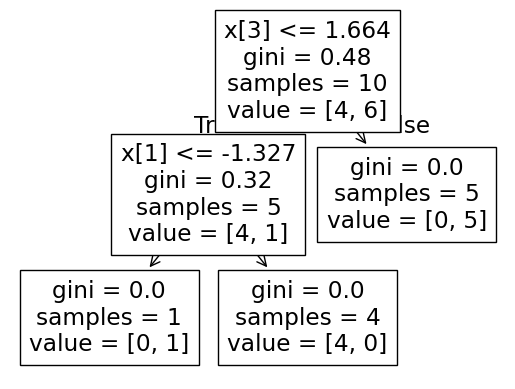

In [18]:
plot_tree(clf2)

[Text(0.5, 0.75, 'x[2] <= 0.986\ngini = 0.42\nsamples = 10\nvalue = [7, 3]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 7\nvalue = [7, 0]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 3\nvalue = [0, 3]'),
 Text(0.625, 0.5, '  False')]

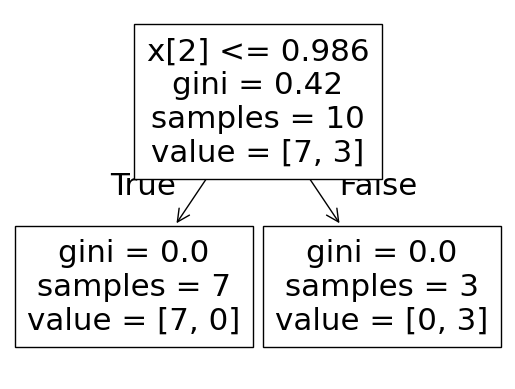

In [19]:
plot_tree(clf3)

In [20]:
clf1.predict(np.array([0.955507,0.972416,0.823973,-0.795320,0.911606]).reshape(1,5))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [21]:
clf2.predict(np.array([0.955507,0.972416,0.823973,-0.795320,0.911606]).reshape(1,5))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

Inference: All the three Decision Trees give zero as the output.

We know that Random Forest gives much better results as compared to any other algorithm. But Why?

The reason is Bias Variance Tradeoff!

The error is made of two things , Bias and Variance, Bias is basically when your ML model is not able to give good results on the training data, this is lao known as HIGH BIAS.

Variance is when your model is good with the training data but not on the test data, this is high variance.

We always want a low bias, low variance (LBLV) in our model. They both are inversely proportional.

Most of the algorithms that we have are, Low Bias and High Variance , an example of this is a fully grown Decision Tree , SVM , KNN.

Another type of algorithms are High Bias and Low varince, examples are Linear Regression and Logistic Regression.

An interesting thing about Random Forests is when a LBLV algorithm is given so it converts it to the ideal Low Bias, Low Variance model.

How does that happen?

We have few base models which are fully grown Decision trees which means they all are Low Bias and High Variance (makes mistakes on the test data). We feed a subset of data to every decision tree and post training, the LB remains the same but when subsets of data is given to sooo many trees in a forests, the noisy data is also equally distributed and which distributes the impact of noisy points and the variance is also reduced

In [22]:
# Example of this through a Code:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles
import matplotlib.pyplot as plt

In [23]:
np.random.seed(42)
X,y = make_circles(n_samples=500, factor=0.1 , noise=0.35, random_state=42)
X_train , X_test, y_train ,y_test = train_test_split(X,y,test_size=0.2)

In [24]:
X.shape

(500, 2)

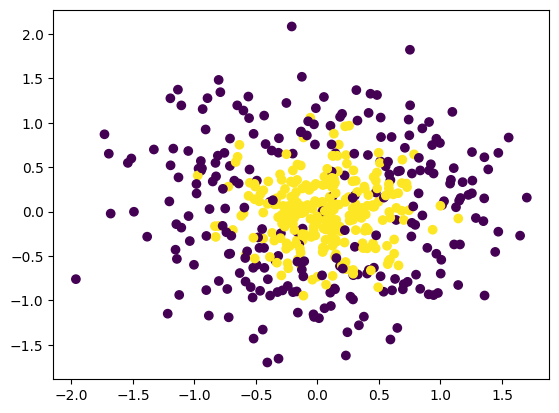

In [25]:
plt.scatter(X[:,0],X[:,1],c=y)

Inference: This is a classification data, which has a upper class and a lower class. And the data is showing concentric circles type of behaviour.

We will first use a Decision Tree to classiy between both the classes and then same goes for Random Forest and then we can compare the performances.

In [26]:
# Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

In [27]:
dtree = DecisionTreeClassifier(random_state=42)
dtree.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42)

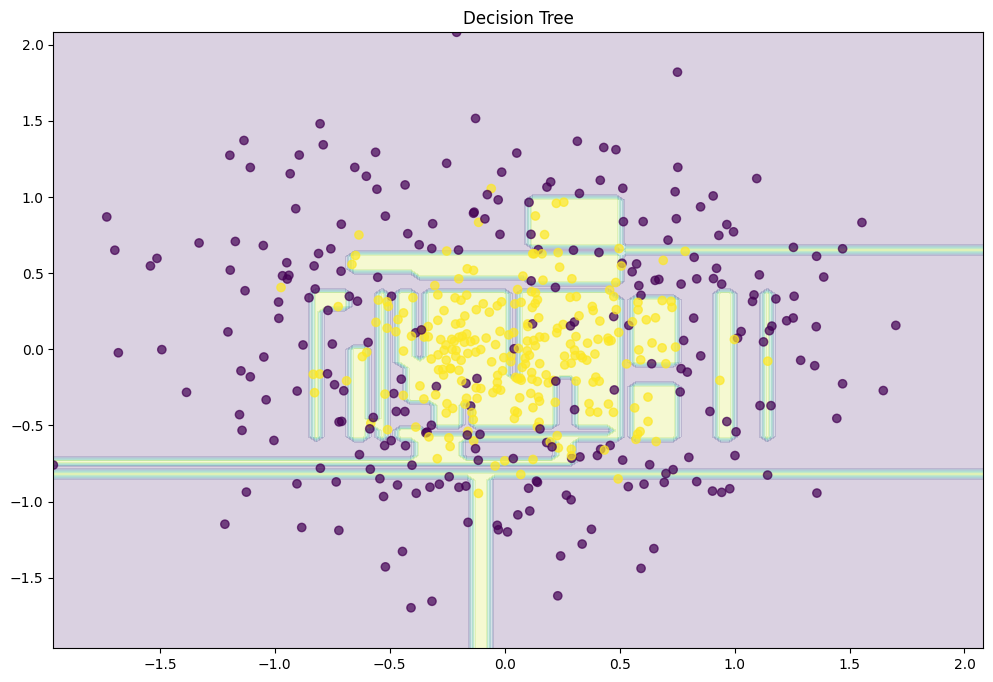

In [28]:
plt.figure(figsize=(12,8))
X_range = np.linspace(X.min(),X.max(),100)
xx1, xx2 = np.meshgrid(X_range , X_range)
y_hat = dtree.predict(np.c_[xx1.ravel() , xx2.ravel()])
y_hat = y_hat.reshape(xx1.shape)
plt.contourf(xx1 , xx2, y_hat , alpha=0.2)
plt.scatter(X[:,0], X[:,1], c=y, cmap='viridis', alpha=0.7)
plt.title("Decision Tree")
plt.show()

Inference: This is a fully grown Decision Tree , with Low Bias and High Variance and the algorithm is overfitting.

In [29]:
# Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

In [30]:
rf = RandomForestClassifier(n_estimators=500 , random_state=42)
rf.fit(X_train , y_train)

RandomForestClassifier(n_estimators=500, random_state=42)

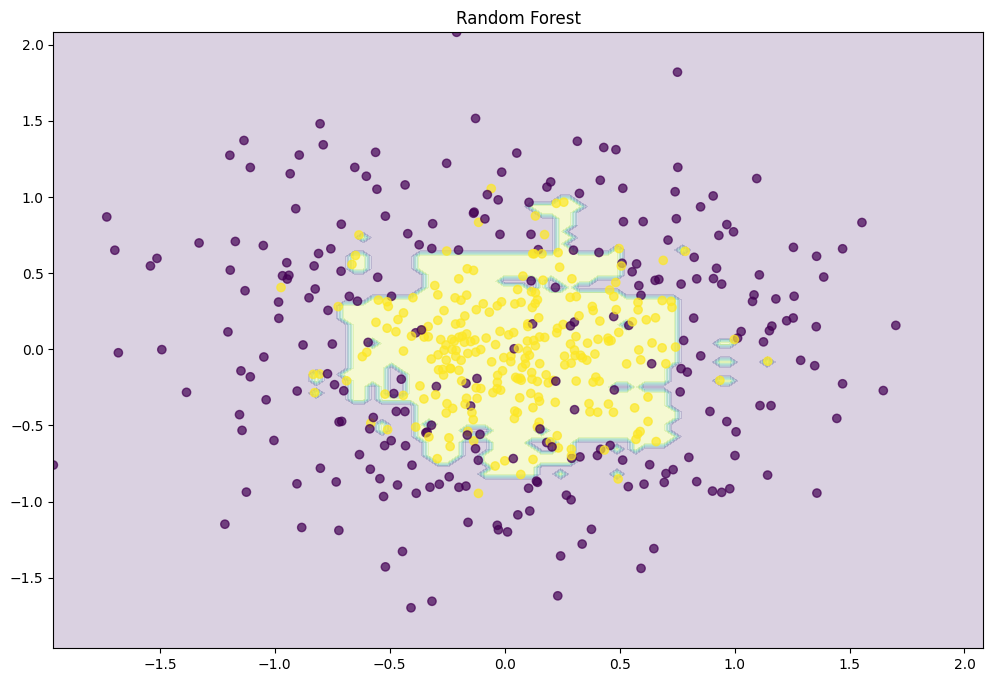

In [31]:
plt.figure(figsize=(12,8))
X_range = np.linspace(X.min() , X.max() , 100)
xx1 , xx2 = np.meshgrid(X_range , X_range)
y_hat = rf.predict(np.c_[xx1.ravel(), xx2.ravel()])
y_hat = y_hat.reshape(xx1.shape)
plt.contourf(xx1 , xx2, y_hat , alpha=0.2)
plt.scatter(X[:,0], X[:,1], c=y, cmap='viridis', alpha=0.7)
plt.title("Random Forest")
plt.show()

Inference: from the graph it can be seen it has Low Bias and Low Variance. Although, the bias has increased a bit but the variance has a decreased a lot, this is what makes Random Forest a great algorithm, because it converts an algorithm to LOW BIAS , LOW VARIANCE algorithm.


Bagging v/s Random Forest
Random Forest internally is an implementation of Bagging, but surely they both are not the same, we are going to list some major and important difference between the two:

Bagging helps us use different algorithms as base models. In short, Bagging is a general technique, used for different algorithms for better results. Whereas, in Random Forests, only and only Decision Trees are used as base algorithms.

so, if we take a decision tree in a bagging method, will it considered a random forest?? NOO. Another difference between the two is that sampling (column or row sampling) in bagging is done at tree level and in Random Forest, it is Node level.(after every node sampling is done)

In [32]:
# Code for Random Forest
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

In [33]:
df = pd.read_csv('heart.csv')

In [34]:
df.head()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [35]:
df.shape

(303, 14)

In [36]:
X = df.iloc[:,0:-1]
y = df.iloc[:,-1]

In [37]:
X_train, X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [38]:
print(X_train.shape)
print(X_test.shape)

(242, 13)
(61, 13)


In [39]:
rf = RandomForestClassifier()
gb = GradientBoostingClassifier()
svc = SVC()
lr = LogisticRegression()

In [40]:
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)
accuracy_score(y_test , y_pred)

0.8688524590163934

In [41]:
gb.fit(X_train,y_train)
y_pred = gb.predict(X_test)
accuracy_score(y_test , y_pred)

0.7704918032786885

In [42]:
svc.fit(X_train,y_train)
y_pred = svc.predict(X_test)
accuracy_score(y_test , y_pred)

0.7049180327868853

In [46]:
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
accuracy_score(y_test , y_pred)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


0.8524590163934426

Comparative studies show that even after the data being linear, Random Forest works with good results.